In [450]:
# Exploracion, perfilamiento, limpieza y preparacion
# librerias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler, StandardScaler, RobustScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error
from importlib.metadata import version
import numpy as np
from importlib.metadata import version

# Descarga del archivo

data = pd.read_csv("C:\\Users\\julia\\Downloads\\Proyecto1.csv")

data_copy = data.copy()
data.head()

,season,weekday,weathersit,temp,atemp,hum,windspeed,cnt,time_of_day
0,Winter,6,Clear,3.28,3.0014,0.81,0.0,16,Night
1,Winter,6,Clear,2.34,1.9982,0.80,0.0,40,Night
2,Winter,6,Clear,2.34,1.9982,0.80,0.0,32,Night
3,Winter,6,Clear,3.28,3.0014,0.75,0.0,13,Night
4,Winter,6,Clear,3.28,3.0014,0.75,0.0,1,Night


In [451]:
# Revision de valores faltantes
# All good
data.isna().sum()

season         0
weekday        0
weathersit     0
temp           0
atemp          0
hum            0
windspeed      0
cnt            0
time_of_day    0
dtype: int64

In [452]:
# Revision de duplicados, hay 42 :(
data.duplicated().sum()

np.int64(42)

In [453]:
#Eliminacion de duplicados
data = data.drop_duplicates()
data.duplicated().sum()

np.int64(0)

In [454]:
# Observo valores de 0 en el windspeed, puede ser anomalo, sin embargo el % de ceros en los datos es muy alto, por lo que no conviene purgar la informacion
# Es probable que sea viento bajo o valores redondeados 
# Dejar ese valor tan bajo puede distorcionar la regresion, pega un salto bruzco entre 0 y 6, para suavizarlo lo mejor es reemplazar ese valor 
# Por valores positivos bajos pero distintos de 0
# Tambien es importante, mantener la informacion de que antes el dato era cero, por lo que ademas de hacer el cambio, se crea una nueva columna (0/1)
# Asi el modelo reconoce que son casos especiales

porcentaje_ceros = (data['windspeed'] == 0).mean() * 100
print(f"Porcentaje de ceros en windspeed: {porcentaje_ceros:.2f}%")
# Tambien observo valores de temperatura y sensacion termica negativos pero concuerda con la epoca del año y el aumento de la velocidad del viento, 
# no me parece que sean valores que puedan generar sesgo

Porcentaje de ceros en windspeed: 12.51%


In [455]:
# Para ello voy a usar el percentil 5 para cambiar los 0s y una variable indicadora low_wind para la nueva columna
windspeed_positivos = data.loc[data['windspeed'] > 0, 'windspeed']
# Percentil 5
valor_pequeño = np.percentile(windspeed_positivos, 5)
print(f"Percentil 5 de windspeed positivo: {valor_pequeño}")
# low_wind 
data['low_wind'] = np.where(data['windspeed'] == 0, 1, 0)
# Reemplazo
data.loc[data['windspeed'] == 0, 'windspeed'] = valor_pequeño
# Revision del low_wind
data.loc[4519]

Percentil 5 de windspeed positivo: 6.0032


season          Summer
weekday              2
weathersit       Clear
temp              24.9
atemp          28.0022
hum               0.79
windspeed       6.0032
cnt                 25
time_of_day    Morning
low_wind             0
Name: 4519, dtype: object

In [456]:
# Para evitar multicolinealidad eliminamos la variable temp, puesto que ya en atemp se conoce la temperatura que perciben las personas en el ambiente
# Al observar los datos y el diccionario se observan 3 variables categoricas que deben ser transformadas a numericas, para 
# continuar con el problema de regresion "season", "weathersit", "time_of_day"
categoricas_cols = ["season", "weathersit", "time_of_day"]
numericas_cols = ["weekday", "atemp", "windspeed","low_wind","cnt","hum"]

# Usamos OneHotEncoder en columnTransformer para tomar los datos categoricos y volverlos numericos en varias columnas, y reintegramos todo en una matriz
# No es posible volverlas numeros 1 como invierno, 2, 3 y 4 sino 1 y 0, porque la regresion toma el numero como si se tuviera mas de una vez invierno 
# sumandolo o multiplicandolo, lo cual no tiene sentido, y seria un error. del mismo modo con las otras variables

preprocessor = ColumnTransformer(
    transformers=[('cat', OneHotEncoder(drop='first', sparse_output=False), categoricas_cols),('num', 'passthrough', numericas_cols)])
y = data["cnt"]
# Se transforman los datos a dnum(datanumerico), eliminando una categoria, pero sin dejar de tenerla en cuenta, si eran cuatro clases posibles
# Pasa a ser 000,001,010, 100 lo cual describe cada uno de los 4 casos en season, y 3 casos en las otras dos varibles
dnum = preprocessor.fit_transform(data)
feature_names = preprocessor.get_feature_names_out()
dnum = pd.DataFrame(dnum, columns=feature_names)
#Limpiamos nombres
dnum.columns = [col.split("__")[1] for col in dnum.columns]
dnum.head()

,season_Spring,season_Summer,season_Winter,weathersit_Heavy Rain,weathersit_Light Rain,weathersit_Mist,time_of_day_Morning,time_of_day_Night,weekday,atemp,windspeed,low_wind,cnt,hum
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,6.0,3.0014,6.0032,1.0,16.0,0.81
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,6.0,1.9982,6.0032,1.0,40.0,0.80
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,6.0,1.9982,6.0032,1.0,32.0,0.80
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,6.0,3.0014,6.0032,1.0,13.0,0.75
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,6.0,3.0014,6.0032,1.0,1.0,0.75


In [457]:
# 3 Construccion del modelo de regresion polinomial valor de semilla 77
# Entrenamiento, dividimos los datos del dataset en 80/20 80 para entrenamiento de los modelos y 20 para el test final
x = dnum.drop(['cnt'], axis="columns")
y = dnum['cnt']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=77)
x.head()

,season_Spring,season_Summer,season_Winter,weathersit_Heavy Rain,weathersit_Light Rain,weathersit_Mist,time_of_day_Morning,time_of_day_Night,weekday,atemp,windspeed,low_wind,hum
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,6.0,3.0014,6.0032,1.0,0.81
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,6.0,1.9982,6.0032,1.0,0.80
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,6.0,1.9982,6.0032,1.0,0.80
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,6.0,3.0014,6.0032,1.0,0.75
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,6.0,3.0014,6.0032,1.0,0.75


In [458]:
# Evitamos que se reptia el intercepto de la regresion lineal (include_bias=False) por si las 🪰
# (Creacion de caracteristicas polinomiales ,Estandarizacion y uso del modelo lineal)
pipeline = Pipeline([('poly', PolynomialFeatures(include_bias=False)),('scaler', StandardScaler()),('model', LinearRegression())])
# Parametros, uso solamente de -RMSE(scoring='neg_root_mean_squared_error') en maximizacion de metricas, se pone negativo (-) 
# Para que tome el RMSE correcto, el de menor error. Y usamos validacion cruzada en k partes en este caso 10, mas requieren mas capacidad de computo 
# Y el random state se encarga de reducir la varianza de la estimacion en caso de que cv sea demasiado alto
kfolds = KFold(n_splits=10, shuffle=True, random_state=77)
# Se usa GridSearchCV para hallar el hiperparametro deseado, 
# Solicitando que se obtenga de la regresion polinomial, con la metrica -RMSE y con la validacion, evaluando el modelo con datos no vistos
# Se toma en scoring -RMSE debido a que GridSearchCV obtiene el hiperparametro ams optimo a partir de su valor mayor. 
# Al entender que un RMSE mejor equivale a un menor error y por lo tanto un mejor modelo es necesario que tenga en cuenta esto y para eso se usa su 
# Valor negativo
grid = GridSearchCV( pipeline,param_grid={'poly__degree': [2, 3]},scoring='neg_root_mean_squared_error',cv=kfolds)
grid.fit(x_train, y_train)

,estimator,Pipeline(step...egression())])
,param_grid,"{'poly__degree': [2, 3]}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,None
,refit,True
,cv,KFold(n_split... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,degree,3


In [459]:
# Se guarda en un diccionario 
resultados = pd.DataFrame(grid.cv_results_)
# Observamos el -RMSE Cuanto varia
# Y que tanto varían esos resultados entre si. Estabilidad
resultados[['param_poly__degree', 'mean_test_score', 'std_test_score']]

,param_poly__degree,mean_test_score,std_test_score
0,2,-132.465412,2.834293
1,3,-129.328767,2.397162


In [460]:
# Bias-variance tradeoff
# El modelo de polinomio grado 3 tiene un menor error, para saber si es mas dependiente de las variables (fold) es necesario 
# Observar por medio de lasso si un hiperparametro alfa que genere un modleo mas complejo es mejor o peor
# Si es dependiente, se vuelve menos estable y es propenso al sobreajuste, ya veremos que sucede en lasso. Comportamiento esperado
# Vemos todas las metricas en los dos parametros, polinomio grado 2 y grado 3
# Error en la cantidad de renta de biciletas
# Actualizamos solo el grado del pipeline y calculamos R² 

# Guardamos resultados del GridSearch del modelo polinomial
resultados_poly = pd.DataFrame(grid.cv_results_)

# Convertimos correctamente el score
# Como usamos scoring='neg_root_mean_squared_error'
# mean_test_score = -RMSE
resultados_poly['RMSE'] = -resultados_poly['mean_test_score']
resultados_poly['MSE'] = resultados_poly['RMSE'] ** 2

# Mostrar métricas por grado
print(resultados_poly[['param_poly__degree', 'RMSE', 'MSE']])
# Grado 2
modelo_g2 = pipeline.set_params(poly__degree=2)
modelo_g2.fit(x_train, y_train)
r2_g2 = r2_score(y_train, modelo_g2.predict(x_train))
print(f"R² entrenamiento grado 2: {r2_g2:.4f}")

# Mejor modelo (grado óptimo según GridSearch)
best_poly = grid.best_estimator_
y_pred_train = best_poly.predict(x_train)
r2_train = r2_score(y_train, y_pred_train)
print(f"R² entrenamiento grado óptimo: {r2_train:.4f}")


   param_poly__degree        RMSE           MSE
0                   2  132.465412  17547.085461
1                   3  129.328767  16725.929956
R² entrenamiento grado 2: 0.4698
R² entrenamiento grado óptimo: 0.5093


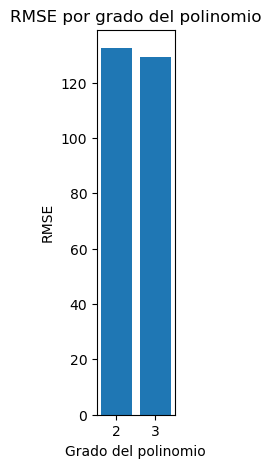

In [461]:
# Se puede observar que el que R2 es bastante bajo por lo que podemos decir que posiblemente se requeiren mas varibles que no estan en el data set
# Para mejorar la explicabilidad del modelo, sin embargo es posible que tamibne haya ruido u otros factores que afecten de manera considerable este
# Valor
# Graficamos
plt.figure(figsize=(1,5))
plt.bar(resultados_poly['param_poly__degree'], resultados_poly['RMSE'])
plt.xlabel('Grado del polinomio')
plt.ylabel('RMSE')
plt.title('RMSE por grado del polinomio')
plt.show()

In [462]:
# Regresion Lasso (penalizando los coeficientes grandes y reduciendo el riesgo de memorizar 
# Ruidos de los datos) eliminando los variables que no son significantes (0)
# Cuanta regularizacion necesita el modelo con base a la metrica RMSE?
# Repetimos el mismo proceso de pipeline para lasso estableciendo la logica y los pasos de procesamiento y modelado
pipeline_lasso = Pipeline([('poly', PolynomialFeatures(degree=3, include_bias=False)),('scaler', StandardScaler()),('model', Lasso(max_iter=10000))])
# Ponemos los alphas solicitados para el desarrollo del problemilla 
param_grid = {'model__alpha': [1, 2, 3, 4, 5]}
kfolds = KFold(n_splits=10, shuffle=True, random_state=77)
# Buscamos el mejor hiperparaametro entre los 5
grid_lasso = GridSearchCV(pipeline_lasso,param_grid,scoring='neg_root_mean_squared_error',cv=kfolds)
grid_lasso.fit(x_train, y_train)


,estimator,Pipeline(step...iter=10000))])
,param_grid,"{'model__alpha': [1, 2, ...]}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,None
,refit,True
,cv,KFold(n_split... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,degree,3


In [463]:
# Hiper parametro #2. alfa de regularizacion. El #1 es el del polinomio grado 3 :)
resultados_lasso = pd.DataFrame(grid_lasso.cv_results_)

# Como usamos scoring='neg_root_mean_squared_error'
# mean_test_score es -RMSE
resultados_lasso['RMSE'] = -resultados_lasso['mean_test_score']
resultados_lasso['MSE'] = resultados_lasso['RMSE'] ** 2

resultados_lasso[['param_model__alpha', 'RMSE', 'MSE']]


,param_model__alpha,RMSE,MSE
0,1,131.846876,17383.598615
1,2,133.273554,17761.840267
2,3,134.254404,18024.245043
3,4,135.045631,18237.322441
4,5,135.722076,18420.481987


In [464]:
# Valores del error
#la regresion polinomial + lasso del entrenamiento es levemente mayor que la de la regresion polinomial sin lasso
rmse_lasso_cv = -grid_lasso.best_score_
mse_lasso_cv = rmse_lasso_cv ** 2

print("Mejor alpha:", grid_lasso.best_params_)
print("RMSE CV:", rmse_lasso_cv)
print("MSE CV:", mse_lasso_cv)


Mejor alpha: {'model__alpha': 1}
RMSE CV: 131.84687563575955
MSE CV: 17383.598614911443


In [465]:
# Ahora post training, probamos con el test
# en la polinomial fisrt
pipeline_poly_final = Pipeline([('poly', PolynomialFeatures(degree=3, include_bias=False)),('scaler', StandardScaler()),('model', LinearRegression())])
# Entrenamos el modelo con el mejor grado del polinomio primero
pipeline_poly_final.fit(x_train, y_train)
# Usamos los valores de test para optener las metricas a evaluar de modelo final y posteriormente comparar con lasso
y_pred_poly = pipeline_poly_final.predict(x_test)

r2_poly = r2_score(y_test, y_pred_poly)
mse_poly = mean_squared_error(y_test, y_pred_poly)
rmse_poly = np.sqrt(mse_poly)

# Luego agregamos lasso (+Lasso)
best_lasso = grid_lasso.best_estimator_
y_pred_lasso = best_lasso.predict(x_test)

r2_lasso = r2_score(y_test, y_pred_lasso)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)

# Comparacion 
r2_poly = r2_score(y_test, y_pred_poly)
mse_poly = mean_squared_error(y_test, y_pred_poly)
rmse_poly = np.sqrt(mse_poly)

comparacion = pd.DataFrame({'Modelo': ['Polinomial', 'Polinomial + Lasso'],'R2': [r2_poly, r2_lasso],'MSE': [mse_poly, mse_lasso],'RMSE': [rmse_poly, rmse_lasso]})

comparacion

,Modelo,R2,MSE,RMSE
0,Polinomial,0.477560,17562.323287,132.522916
1,Polinomial + Lasso,0.451411,18441.347424,135.798923


Total variables: 454
Variables eliminadas por Lasso: 368
Variables activas: 86
Porcentaje eliminado: 81.06 %

Top variables más importantes:


,Variable,Coeficiente,Abs
9,atemp,82.930770,82.930770
7,time_of_day_Night,-74.411998,74.411998
77,time_of_day_Night atemp,-21.492458,21.492458
69,time_of_day_Morning^2,-21.456214,21.456214
4,weathersit_Light Rain,-19.470992,19.470992
2,season_Winter,-18.395181,18.395181
444,atemp^3,-16.738906,16.738906
40,season_Winter time_of_day_Night,13.254324,13.254324
75,time_of_day_Night^2,-13.171547,13.171547
435,weekday^2 atemp,12.256667,12.256667


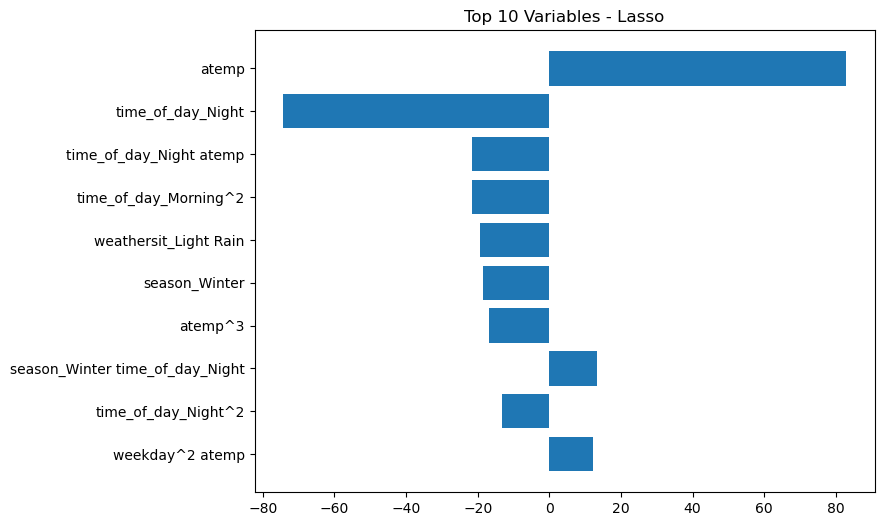

In [466]:
# Bueno, resulta que con el mejor hiperparametro alpha 1 obtenido de lasso no disminuye el error 
# Sino que aumenta, entonces el modelo no estaba sobreajustado, el R2 disminuye tambien
# Por lo que lasso está penalizando coeficientes que sí aportaban información útil, reduciendo la flexibilidad del modelo.
# Bueno ahora vamos a ver con lasso, los coeficientes y las variables. elimino bastantes 368/454 y dejo solo 86
# El mejor modelo es el de la regresion polinomial de grado 3
est_model = grid_lasso.best_estimator_
coeficientes = best_model.named_steps['model'].coef_
feature_names = best_model.named_steps['poly'].get_feature_names_out()
coef_df = pd.DataFrame({'Variable': feature_names,'Coeficiente': coeficientes})
coef_df['Abs'] = coef_df['Coeficiente'].abs()
total_vars = len(coef_df)
vars_cero = (coef_df['Coeficiente'] == 0).sum()
vars_no_cero = total_vars - vars_cero
print("Total variables:", total_vars)
print("Variables eliminadas por Lasso:", vars_cero)
print("Variables activas:", vars_no_cero)
print("Porcentaje eliminado:", round(vars_cero/total_vars*100, 2), "%")
top_n = 10
coef_df_no_cero = coef_df[coef_df['Coeficiente'] != 0] \
    .sort_values(by='Abs', ascending=False)
print("\nTop variables más importantes:")
display(coef_df_no_cero.head(top_n))
coef_top_plot = coef_df_no_cero.head(top_n)
plt.figure(figsize=(8,6))
plt.barh(coef_top_plot['Variable'], coef_top_plot['Coeficiente'])
plt.gca().invert_yaxis()
plt.title("Top 10 Variables - Lasso")
plt.show()

In [467]:
# Podemos observar que, con amplia diferencia, las variables mas importantes para el modelo son la sensacion termica (atemp) 
# Y la parte del dia (time_of_day), especialmente la noche.
# Estas dos variables, una numérica (atemp) y otra categórica (time_of_day_Night), tienen coeficientes absolutos aproximadamente
# Cuatro veces mayores que la mayoria del resto de variables activas, lo que indica su alta influencia en la prediccion.
# Además, también destacan combinaciones y transformaciones de estas variables, como la interaccion entre time_of_day_Night y atemp
# Y las potencias cuadráticas y cubicas de atemp y time_of_day_Morning, lo que sugiere que tanto los efectos lineales como no 
# Lineales de estas variables son relevantes.
# Su contribucion relativa al total de la importancia de todas las variables activas es de solo 32.6%, por lo que no supera el 50%. 
# Esto indica que, aunque son influyentes, el resto de variables también aporta significativamente a la predicción.

# Nombres de las dos variables mas importantes
# Suma de coeficientes absolutos de las dos principales
# Suma de coeficientes absolutos de todas las demas
top2_vars = ['atemp', 'time_of_day_Night']
suma_top2 = coef_df[coef_df['Variable'].isin(top2_vars)]['Abs'].sum()
suma_restantes = coef_df[~coef_df['Variable'].isin(top2_vars)]['Abs'].sum()

# Porcentaje relativo
porcentaje_top2 = suma_top2 / (suma_top2 + suma_restantes) * 100
porcentaje_restantes = suma_restantes / (suma_top2 + suma_restantes) * 100

print(f"Suma coeficientes top 2: {suma_top2:.2f}")
print(f"Suma coeficientes resto: {suma_restantes:.2f}")
print(f"Porcentaje top 2: {porcentaje_top2:.2f}%")
print(f"Porcentaje resto: {porcentaje_restantes:.2f}%")

# Curiosidad, observacion cantidad de repeticion en cierto numeroo de rentas, y dia con maximas y minimas rentas
max_val = y.max()
min_val = y.min()
print("Valor máximo:", max_val)
print("Valor mínimo:", min_val)
promedio_rentas = np.mean(y_test)  # o el dataset de rentas reales que tengas
porcentaje_error_promedio = (rmse_poly / promedio_rentas) * 100
print(f"Error relativo respecto al promedio: {porcentaje_error_promedio:.2f}%")
y.value_counts().sort_index()

Suma coeficientes top 2: 157.34
Suma coeficientes resto: 324.94
Porcentaje top 2: 32.62%
Porcentaje resto: 67.38%
Valor máximo: 977.0
Valor mínimo: 1.0
Error relativo respecto al promedio: 70.12%


cnt
1.0      150
2.0      203
3.0      220
4.0      228
5.0      255
        ... 
967.0      1
968.0      1
970.0      1
976.0      1
977.0      1
Name: count, Length: 869, dtype: int64

In [469]:
# Analisis de resultados 

# Preguntas
# ¿Cuál es el grado de la transformación polinomial que fue seleccionado utilizando la técnica de validación?

# Grado 3 

# ¿Cuál fue el valor de α que fue seleccionado utilizando la técnica de validación para la regresión Lasso?

# Alpha 1

# A partir de la tabla comparativa, ¿Cuál modelo ofrece el mejor rendimiento sobre el conjunto test? 

# Polinomial G3 R^2 0.47756  MSE 17562.323287   RMSE 132.522916    vs    Polinomial G3 + Lasso	 R^2 0.451411	MSE 18441.347424	RMSE 135.798923

# El modelo que ofrece un mejor rendimiento es el de regresion polinomial de grado 3

#¿Qué interpretación puedes darles a los valores obtenidos sobre las métricas de rendimiento?
# El modelo de regresion polinomial de grado 3(P3), presenta un error cuadratico medio mas bajo, esto indica que
# El modelo sin lasso es mas eficaz, por lo que no hay sobreajuste, podemos ver con RMSE que en promedio, el modelo mas eficaz se desvia
# 132.52 en cantidad de bicicletas rentadas en su prediccion, en comparacion a 135.79 del otro modelo, la variacion entre las predicciones fue de 3.27 
# Unidades, lo que representa una discrepancia aunque pequeña, es de mas de 3 unidades de error.

# El modelo (P3) en general tiene un error relativamente alto. Sin embargo, considerando que el rango de rentas varía entre 1 y 977 bicicletas, el % 
# De error representa solo un 13,56% (132.5) de esa variación. Al comparar esto con la frecuencia de alquileres en dias con baja demanda, se observa 
# Que el rango amplio de valores hace que algunas predicciones parezcan menos precisas.

# La mayor cantidad de rentas ocurre en valores bajos, que son mas regulares y periodicos. En cambio, las rentas altas son menos frecuentes y mas 
# Irregulares. por eso, aunque el promedio de rentas sea alrededor de 132.5, el modelo tiene un error relativo alto (70.12%), lo que indica que 
# La prediccion todavia no logra captar bien la variabilidad, especialmente en los valores mas extremos.
# Esto puede deberse a la ausencia de variables importantes que no están contempladas en el dataset. Esto se refleja tambien en el valor de R^2, 
# Que no alcanza el 50%, indicando que el modelo solo explica parcialmente la variabilidad de los datos.


# ¿Cuáles variables fueron seleccionadas con el modelo Lasso? A partir de estas, ¿Qué interpretación de cara al problema puedes dar? 

# Las variables mas relevantes obtenidas a partir del modelo Lasso son, sin duda, la sensacion térmica y el tiempo del dia (noche). 
# Esto indica que la demanda de bicicletas esta fuertemente influenciada por el clima y el momento del dia: temperaturas extremas  
# reducen o aumentan la cantidad de rentas, y por la noche la actividad disminuye, mientras que durante el dia, 
# Se observa un mayor uso. Por lo tanto, estas variables reflejan patrones de comportamiento de los usuarios.

# Reflexiona sobre cómo este nuevo conocimiento podría ayudar a tomar decisiones en el contexto del problema.

# El conocimiento obtenido a partir del analisis y modelado de la demanda de bicicletas aporta informacion clave para la toma de decisiones 
# En la gestion del servicio. Saber que la sensacion termica y el momento del dia son factores determinantes permite ajustar la disponibilidad 
# De bicicletas y recursos segun las condiciones climaticas y horarios, optimizando la operacion y mejorando la satisfaccion del usuario.
# Ademas, entender que la demanda tiene gran variabilidad, con picos irregulares en rentas altas, sugiere que es necesario monitorear y 
# Prepararse para esos momentos especiales, quizas con estrategias dinamicas o promociones.
# Por ultimo, el reconocimiento de que el modelo aun no explica toda la variabilidad indica la oportunidad de incorporar nuevas variables o 
# Fuentes de datos (como eventos especiales, calidad del aire o trafico) para mejorar la precision y tomar decisiones mas informadas y efectivas.
